# Dynamic-Curvature Hyperbolic Continual Learning: benchmarks
**Euclidean · Euclidean+EWC · Hyperbolic (fixed c) · Dynamic curvature (ours)** on Split-CIFAR100 and Split-MiniImageNet, using real Kaggle data only.

**Before you start:** Runtime → Change runtime type → **T4 GPU**. Add `KAGGLE_USERNAME` and `KAGGLE_KEY` under 🔑 Secrets in the left sidebar (kaggle.com → Settings → API → Create New Token), and turn on notebook access.

### Setup (once per session)

In [2]:
import os, sys
from google.colab import drive

drive.mount('/content/drive')

DRIVE = '/content/drive/MyDrive'
DATA = f'{DRIVE}/hmcl_data'
RESULTS = f'{DRIVE}/hmcl_results_gpu'
os.makedirs(DATA, exist_ok=True)
os.makedirs(RESULTS, exist_ok=True)

%cd /content

REPO, BRANCH = 'https://github.com/Tarungowdap/HUBERILT-HMCL_ICML.git', 'main'
!rm -rf /content/hmcl
!git clone -q --depth 1 -b {BRANCH} {REPO} /content/hmcl

%cd /content/hmcl
!pip install -q kagglehub
sys.path.insert(0, '/content/hmcl')

from google.colab import userdata
import getpass

try:
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    print("Kaggle credentials loaded successfully from Colab Secrets.")
except Exception as e:
    print("\nKaggle Secrets not found in Colab Secrets panel!")
    print("Please enter your Kaggle credentials below to proceed:\n")
    os.environ['KAGGLE_USERNAME'] = input("Enter your Kaggle Username: ").strip()
    os.environ['KAGGLE_KEY'] = getpass.getpass("Enter your Kaggle API Key (invisible typing): ").strip()
    print("\nCredentials set for this session.")

import torch
assert torch.cuda.is_available(), 'No GPU found: Runtime -> Change runtime type -> T4 GPU, then run this cell again'
DEVICE = torch.device('cuda')
torch.backends.cudnn.benchmark = True
print('Device:', DEVICE, '|', torch.cuda.get_device_name(0),
      f'| {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content
/content/hmcl

Kaggle Secrets not found in Colab Secrets panel!
Please enter your Kaggle credentials below to proceed:

Enter your Kaggle Username: tarungowdap020806
Enter your Kaggle API Key (invisible typing): ··········

Credentials set for this session.
Device: cuda | Tesla T4 | 15.6 GB


### Step 1: Load the datasets from Kaggle
The first run downloads and resizes the data, then caches it in Drive. Later runs take seconds. Each dataset should show 5000 train and 1000 test images per task.

In [5]:
import importlib, torch, hmcl_cl as H
importlib.reload(H)
from pathlib import Path

DEVICE = torch.device('cuda')
BENCHMARKS = {
    'split_cifar100':     (10, 10, 32, 'fedesoriano/cifar100'),
    'split_miniimagenet': (10, 10, 64, 'arjunashok33/miniimagenet'),
}
NORM = {'split_cifar100': ((0.507, 0.487, 0.441), (0.267, 0.256, 0.276)),
        'split_miniimagenet': ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))}

def load_stream(ds, seed):
    tasks, cpt, size, slug = BENCHMARKS[ds]
    return H.build_stream(ds, Path(DATA), tasks, cpt, size, seed, DEVICE, 'kaggle', slug)

streams = {}
for ds in BENCHMARKS:
    print(f'\n--- {ds} ---')
    streams[ds] = load_stream(ds, seed=0)
    n_tr = [len(v['train_y']) for v in streams[ds].values()]
    n_te = [len(v['test_y']) for v in streams[ds].values()]
    print(f'  images per task: train {min(n_tr)}-{max(n_tr)}, test {min(n_te)}-{max(n_te)}')
print('\nDatasets ready.')


--- split_cifar100 ---
Using Colab cache for faster access to the 'cifar100' dataset.
  files at /kaggle/input/cifar100
  50000 train / 10000 test, 100 classes, cached to /content/drive/MyDrive/hmcl_data/kaggle_fedesoriano__cifar100_32.npz
split_cifar100: 10 tasks x 10 classes, 50000 train / 10000 test images, image shape (3, 32, 32)
  images per task: train 5000-5000, test 1000-1000

--- split_miniimagenet ---


100%|██████████| 6.28G/6.28G [01:05<00:00, 103MB/s] 

Extracting files...


  files at /root/.cache/kagglehub/datasets/arjunashok33/miniimagenet/versions/1
  image folders: /root/.cache/kagglehub/datasets/arjunashok33/miniimagenet/versions/1 (100 classes, no test split), resizing to 64px ...
  50000 train / 10000 test, 100 classes, cached to /content/drive/MyDrive/hmcl_data/kaggle_arjunashok33__miniimagenet_64.npz
split_miniimagenet: 10 tasks x 10 classes, 50000 train / 10000 test images, image shape (3, 64, 64)
  images per task: train 5000-5000, test 1000-1000

Datasets ready.


### Step 2: Train all methods on both Split benchmarks
Euclidean, Euclidean + EWC, Hyperbolic (fixed c) and Dynamic curvature (ours). Finished runs are skipped, so the cell can be re-run after a disconnect. The second cell keeps only the seeds that every method finished.

In [7]:

import os, json, time

METHODS  = ['euclidean', 'ewc', 'hmcl', 'dynamic-curvature']
SEEDS    = [0, 1]
EPOCHS   = {'split_cifar100': 10, 'split_miniimagenet': 4}
SETTINGS = dict(width=64, embed_dim=64, batch_size=128, lr=1e-3, amp=1)

def result_file(ds, m, seed):
    os.makedirs(f'{RESULTS}/{ds}', exist_ok=True)
    return f'{RESULTS}/{ds}/{m}__seed{seed}.json'

def train(ds, methods=METHODS, seeds=SEEDS):
    t0 = time.time()
    for seed in seeds:
        stream = streams[ds] if seed == 0 else load_stream(ds, seed)
        for m in methods:
            f = result_file(ds, m, seed)
            if os.path.exists(f):
                print(f'skip {ds} / {m} / seed {seed} (done)'); continue
            aug = H.GPUAugment(*NORM[ds], pad=BENCHMARKS[ds][2] // 8)
            args = H.make_args(epochs=EPOCHS[ds], **SETTINGS)
            r = H.run_experiment(m, stream, args, seed, DEVICE, aug)
            r.update(dataset=ds, settings={**SETTINGS, 'epochs': EPOCHS[ds]})
            json.dump(r, open(f, 'w'), indent=1)
            print(f'   saved {f}  [{(time.time() - t0) / 60:.1f} min so far]')
        if seed != 0:
            del stream; torch.cuda.empty_cache()
    print(f'\n{ds}: done in {(time.time() - t0) / 60:.1f} min')

print('Methods:', [H.METHOD_LABELS[m] for m in METHODS], '| seeds:', SEEDS, '| epochs:', EPOCHS)
train('split_cifar100')
train('split_miniimagenet')
print(f'\nAll training done. Results in {RESULTS}')

Methods: ['Euclidean', 'Euclidean + EWC', 'Hyperbolic (fixed c)', 'Dynamic curvature (ours)'] | seeds: [0, 1] | epochs: {'split_cifar100': 10, 'split_miniimagenet': 4}

  Euclidean [euclidean]  seed=0  (10 tasks)
    task 1 epoch 10/10 loss=1.0187
  After task 1: task-IL avg=57.80%  class-IL avg=57.80%  [task-IL per task: 57.8]
    task 2 epoch 10/10 loss=0.5779
  After task 2: task-IL avg=55.00%  class-IL avg=36.25%  [task-IL per task: 38.8, 71.2]
    task 3 epoch 10/10 loss=0.4144
  After task 3: task-IL avg=51.67%  class-IL avg=29.83%  [task-IL per task: 28.4, 45.3, 81.3]
    task 4 epoch 10/10 loss=0.6700
  After task 4: task-IL avg=51.60%  class-IL avg=23.30%  [task-IL per task: 30.4, 46.9, 58.8, 70.3]
    task 5 epoch 10/10 loss=0.4812
  After task 5: task-IL avg=50.52%  class-IL avg=19.92%  [task-IL per task: 25.4, 48.4, 51.2, 53.3, 74.3]
    task 6 epoch 10/10 loss=0.4750
  After task 6: task-IL avg=48.22%  class-IL avg=17.57%  [task-IL per task: 22.1, 40.0, 52.3, 44.9, 54.7, 7

/content/hmcl/hmcl_cl/train.py:225: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


    task 1 epoch 10/10 loss=0.5818
  After task 1: task-IL avg=61.50%  class-IL avg=61.50%  [task-IL per task: 61.5] | c=0.1000
    task 2 epoch 10/10 loss=0.3212
  After task 2: task-IL avg=53.35%  class-IL avg=36.80%  [task-IL per task: 33.1, 73.6] | c=0.1000
    task 3 epoch 10/10 loss=0.2384
  After task 3: task-IL avg=54.30%  class-IL avg=27.00%  [task-IL per task: 29.1, 52.8, 81.0] | c=0.1000
    task 4 epoch 10/10 loss=0.3730
  After task 4: task-IL avg=48.40%  class-IL avg=17.10%  [task-IL per task: 27.8, 45.8, 51.6, 68.4] | c=0.1000
    task 5 epoch 10/10 loss=0.2596
  After task 5: task-IL avg=49.64%  class-IL avg=14.96%  [task-IL per task: 26.7, 47.1, 55.3, 44.3, 74.8] | c=0.1000
    task 6 epoch 10/10 loss=0.2509
  After task 6: task-IL avg=49.32%  class-IL avg=12.62%  [task-IL per task: 28.5, 42.5, 45.3, 46.7, 57.3, 75.6] | c=0.1000
    task 7 epoch 10/10 loss=0.2803
  After task 7: task-IL avg=49.01%  class-IL avg=10.14%  [task-IL per task: 28.9, 46.0, 52.2, 39.5, 54.4, 5

KeyboardInterrupt: 

In [8]:
import os, glob, shutil
METHODS = ['euclidean', 'ewc', 'hmcl', 'dynamic-curvature']
for ds in ['split_cifar100', 'split_miniimagenet']:
    files = glob.glob(f'{RESULTS}/{ds}/*__seed*.json')
    done = {m: {int(f.split('__seed')[1][:-5]) for f in files if os.path.basename(f).startswith(m + '__')} for m in METHODS}
    common = set.intersection(*done.values()) if all(done.values()) else set()
    print(f'{ds}: seeds finished per method {done} -> using seeds {sorted(common)}')
    for f in files:
        m, s = os.path.basename(f)[:-5].split('__seed')
        if m in METHODS and int(s) not in common:
            os.makedirs(f'{RESULTS}/incomplete/{ds}', exist_ok=True)
            shutil.move(f, f'{RESULTS}/incomplete/{ds}/')
            print('   moved aside (not all methods have this seed):', os.path.basename(f))

split_cifar100: seeds finished per method {'euclidean': {0, 1}, 'ewc': {0, 1}, 'hmcl': {0, 1}, 'dynamic-curvature': {0, 1}} -> using seeds [0, 1]
split_miniimagenet: seeds finished per method {'euclidean': {0}, 'ewc': {0}, 'hmcl': {0}, 'dynamic-curvature': {0}} -> using seeds [0]


### Step 3: Benchmarks
Tables (mean ± std, % improvement, p-values) and all charts.

# Split-CIFAR100

epochs: {10} | seeds: [0, 1]


### Results (mean ± std over seeds)
| Method | Seeds | Task-IL acc | Task-IL forgetting | Class-IL acc | Class-IL forgetting | Curvature c |
|---|---|---|---|---|---|---|
| Euclidean | 2 | 50.38 ± 1.43 | 26.34 ± 1.29 | 12.39 ± 0.33 | 61.21 ± 0.71 | — |
| Euclidean + EWC | 2 | 54.65 ± 1.14 | 18.24 ± 1.22 | 15.79 ± 0.28 | 48.81 ± 0.05 | — |
| Hyperbolic (fixed c) | 2 | 45.96 ± 1.13 | 30.43 ± 1.23 | 7.60 ± 0.21 | 73.03 ± 0.19 | 0.100 → 0.100 |
| **Dynamic curvature (ours)** | 2 | 60.45 ± 0.98 | 5.59 ± 0.81 | 23.14 ± 0.96 | 24.28 ± 0.38 | 0.097 → 0.089 |


### How much better is Dynamic curvature (ours)?
| Compared with | Setting | Forgetting (baseline → ours) | Forgetting reduction | Accuracy (baseline → ours) | Accuracy gain | p-value (forgetting) |
|---|---|---|---|---|---|---|
| Euclidean | Task-IL | 26.34 → 5.59 | **79% less** | 50.38 → 60.45 | +10.07 pts (+20%) | 0.0642 |
| Euclidean | Class-IL | 61.21 → 24.28 | **60% less** | 12.39 → 23.14 | +10.76 pts (+87%) | 0.0057 |
| Euclidean + EWC | Task-IL | 18.24 → 5.59 | **69% less** | 54.65 → 60.45 | +5.80 pts (+11%) | 0.1010 |
| Euclidean + EWC | Class-IL | 48.81 → 24.28 | **50% less** | 15.79 → 23.14 | +7.35 pts (+47%) | 0.0111 |
| Hyperbolic (fixed c) | Task-IL | 30.43 → 5.59 | **82% less** | 45.96 → 60.45 | +14.49 pts (+32%) | 0.0520 |
| Hyperbolic (fixed c) | Class-IL | 73.03 → 24.28 | **67% less** | 7.60 → 23.14 | +15.54 pts (+204%) | 0.0075 |


Success metric (vs Euclidean + EWC): Task-IL: 69% less forgetting (p=0.1010) | Class-IL: 50% less forgetting (p=0.0111)


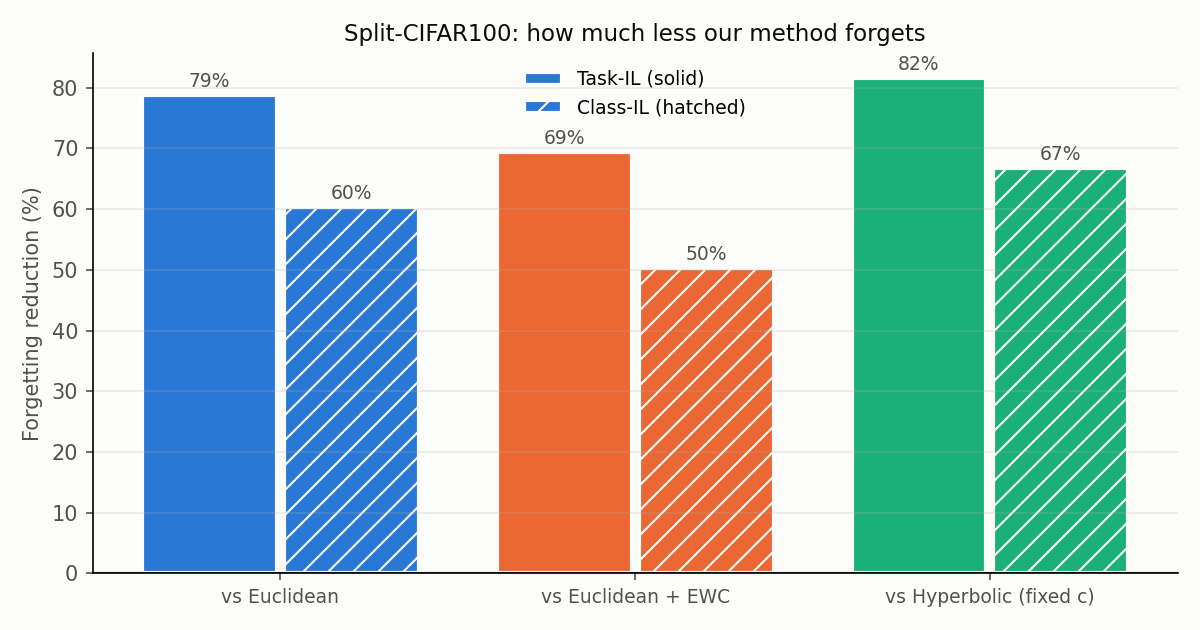

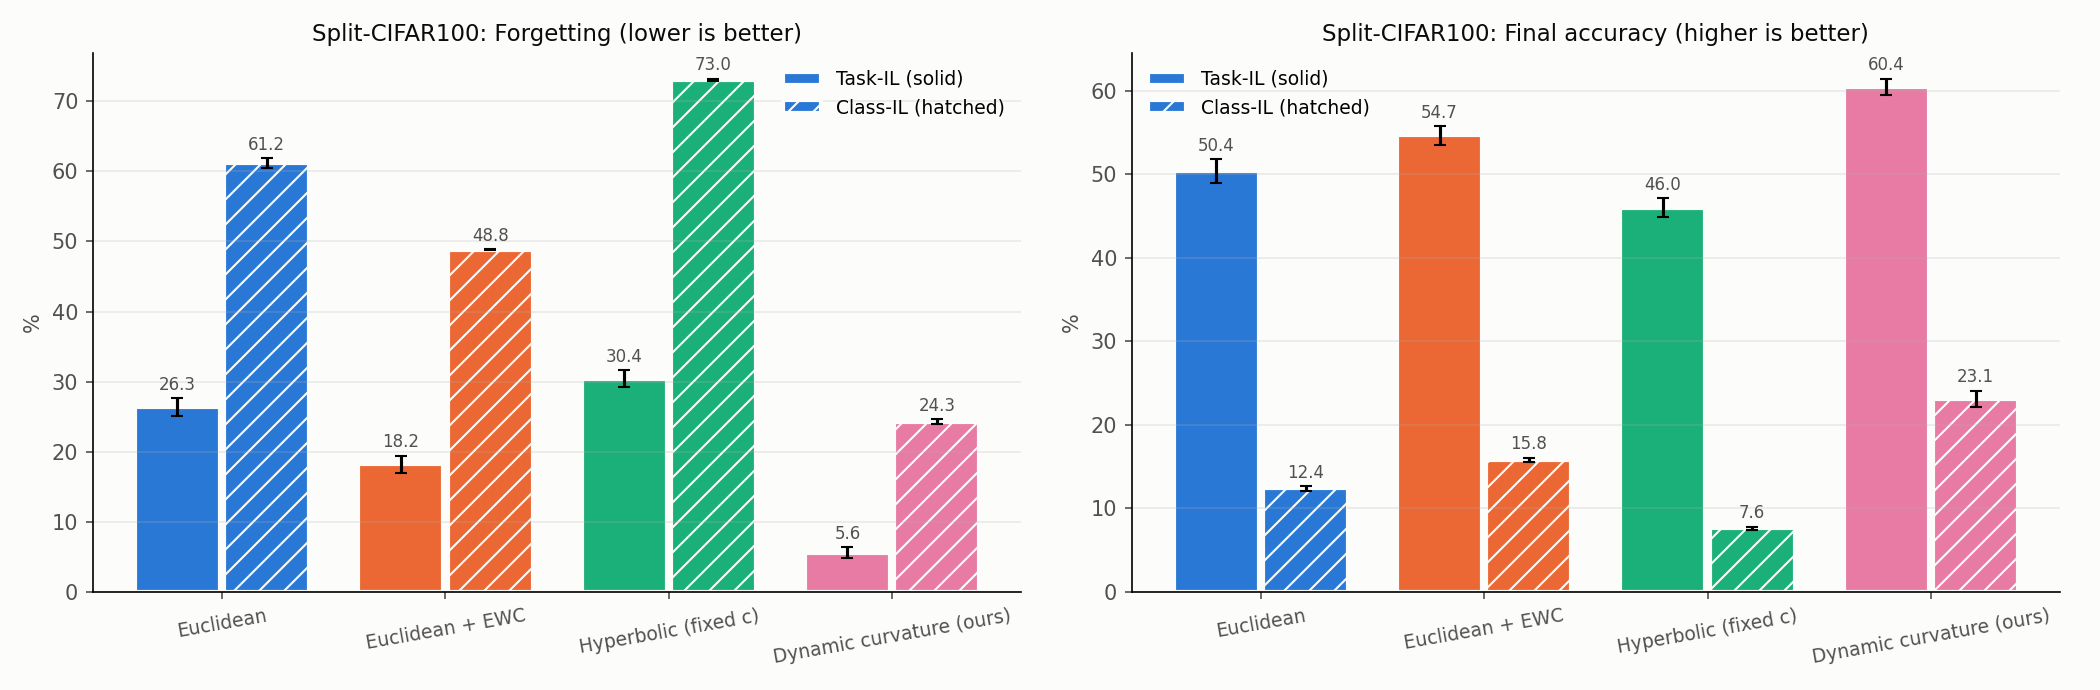

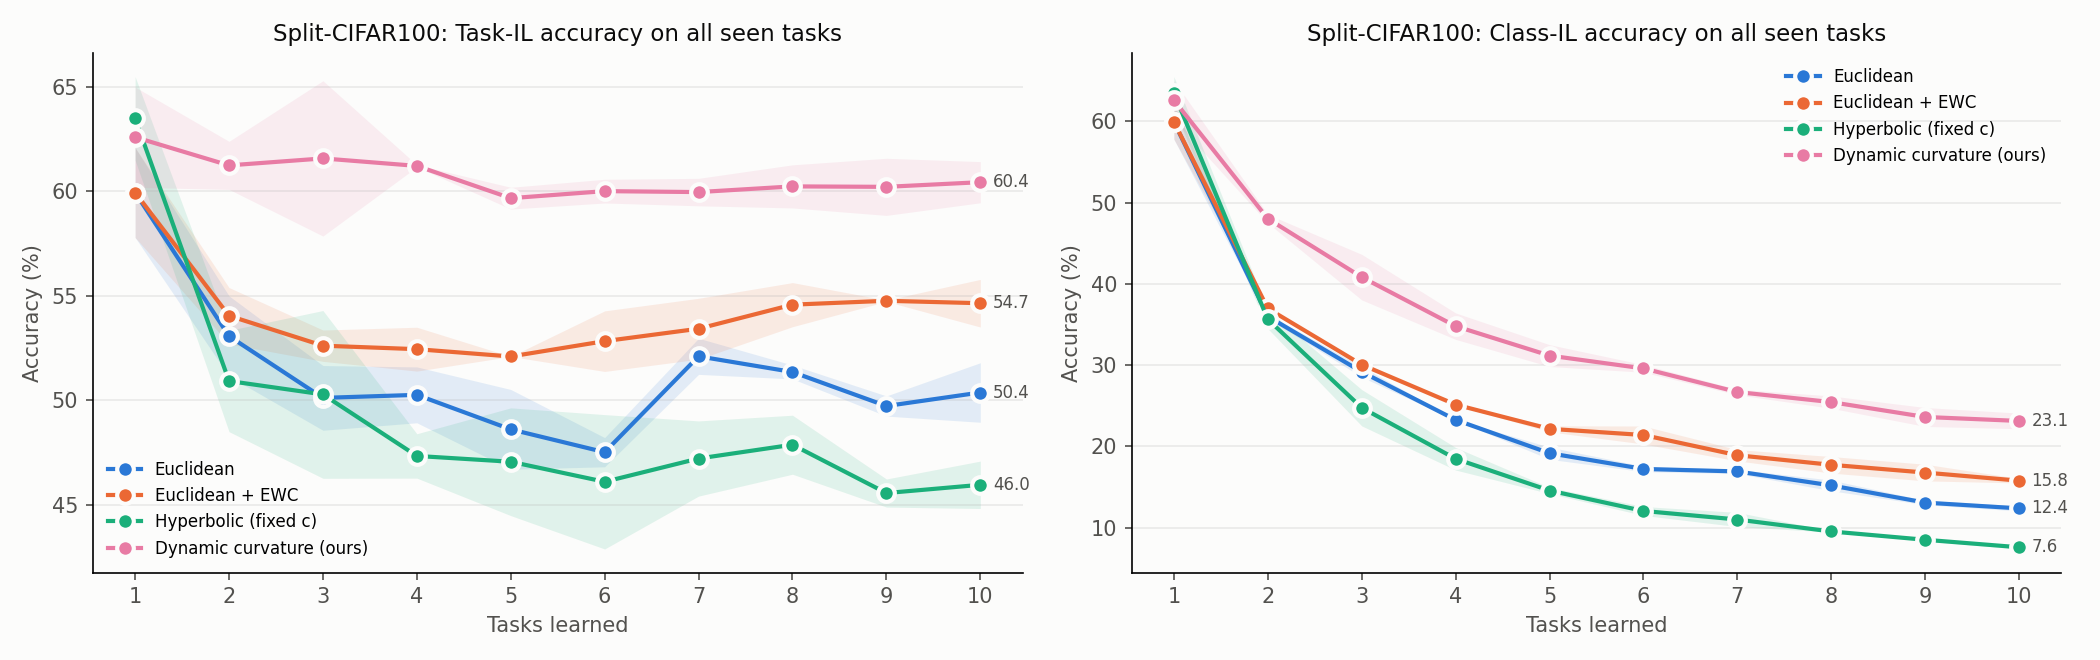

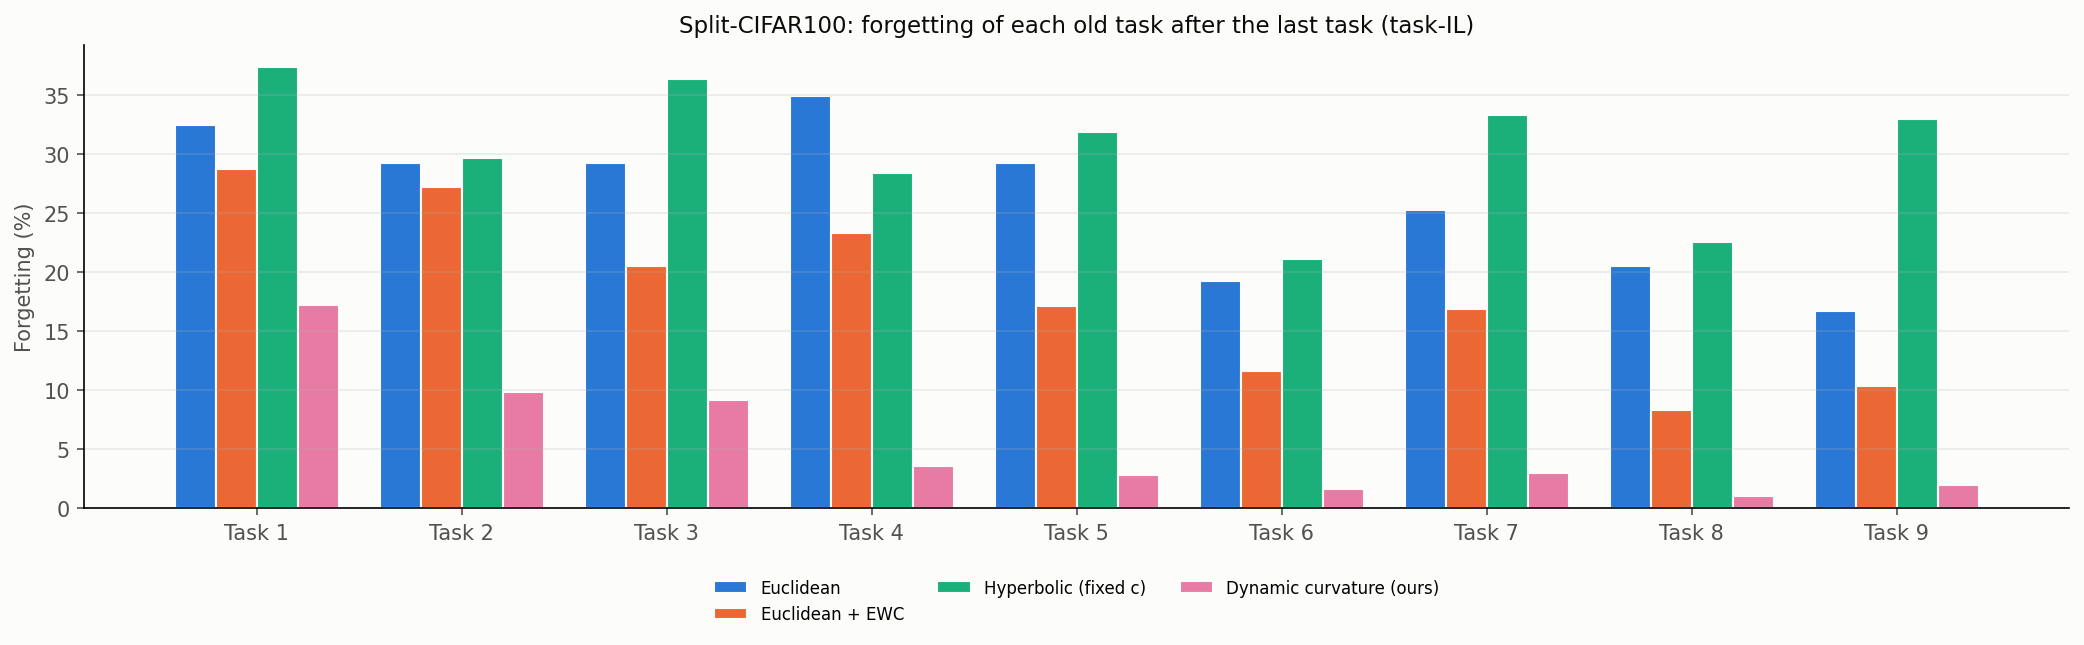

# Split-MiniImageNet

epochs: {4} | seeds: [0]


### Results (mean ± std over seeds)
| Method | Seeds | Task-IL acc | Task-IL forgetting | Class-IL acc | Class-IL forgetting | Curvature c |
|---|---|---|---|---|---|---|
| Euclidean | 1 | 35.59 | 21.11 | 6.91 | 44.59 | — |
| Euclidean + EWC | 1 | 39.31 | 15.03 | 9.35 | 38.04 | — |
| Hyperbolic (fixed c) | 1 | 35.90 | 29.30 | 5.75 | 62.80 | 0.100 → 0.100 |
| **Dynamic curvature (ours)** | 1 | 51.39 | 5.86 | 16.63 | 22.78 | 0.098 → 0.086 |


### How much better is Dynamic curvature (ours)?
| Compared with | Setting | Forgetting (baseline → ours) | Forgetting reduction | Accuracy (baseline → ours) | Accuracy gain | p-value (forgetting) |
|---|---|---|---|---|---|---|
| Euclidean | Task-IL | 21.11 → 5.86 | **72% less** | 35.59 → 51.39 | +15.80 pts (+44%) | n/a (1 seed) |
| Euclidean | Class-IL | 44.59 → 22.78 | **49% less** | 6.91 → 16.63 | +9.72 pts (+141%) | n/a (1 seed) |
| Euclidean + EWC | Task-IL | 15.03 → 5.86 | **61% less** | 39.31 → 51.39 | +12.08 pts (+31%) | n/a (1 seed) |
| Euclidean + EWC | Class-IL | 38.04 → 22.78 | **40% less** | 9.35 → 16.63 | +7.28 pts (+78%) | n/a (1 seed) |
| Hyperbolic (fixed c) | Task-IL | 29.30 → 5.86 | **80% less** | 35.90 → 51.39 | +15.49 pts (+43%) | n/a (1 seed) |
| Hyperbolic (fixed c) | Class-IL | 62.80 → 22.78 | **64% less** | 5.75 → 16.63 | +10.88 pts (+189%) | n/a (1 seed) |


Success metric (vs Euclidean + EWC): Task-IL: 61% less forgetting (p n/a: 1 seed) | Class-IL: 40% less forgetting (p n/a: 1 seed)


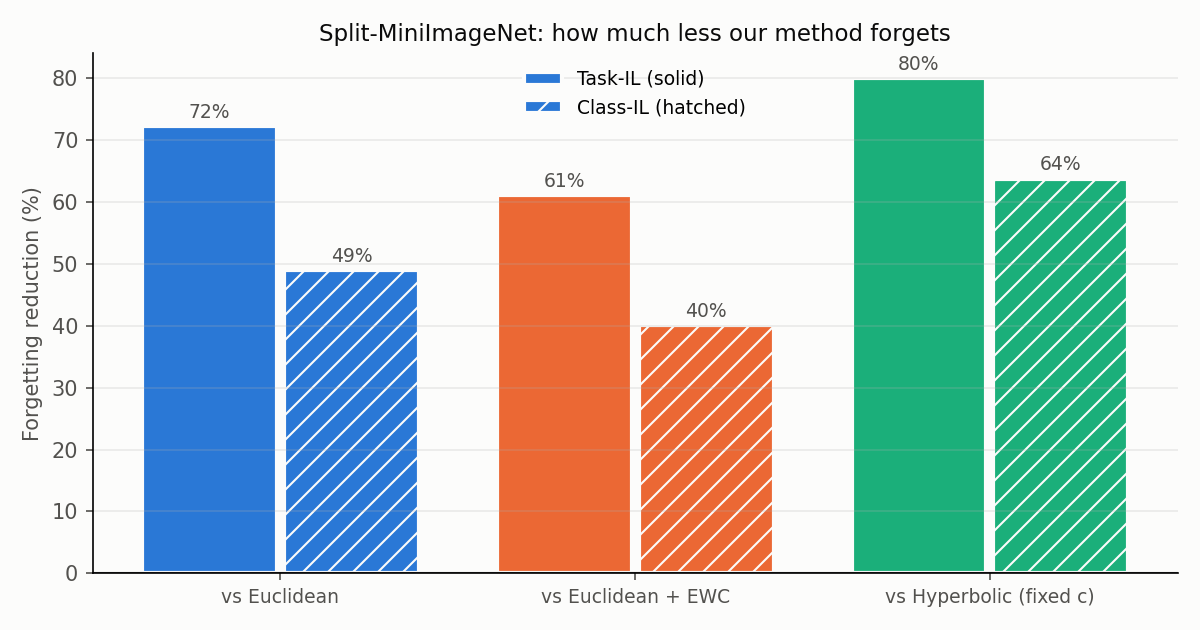

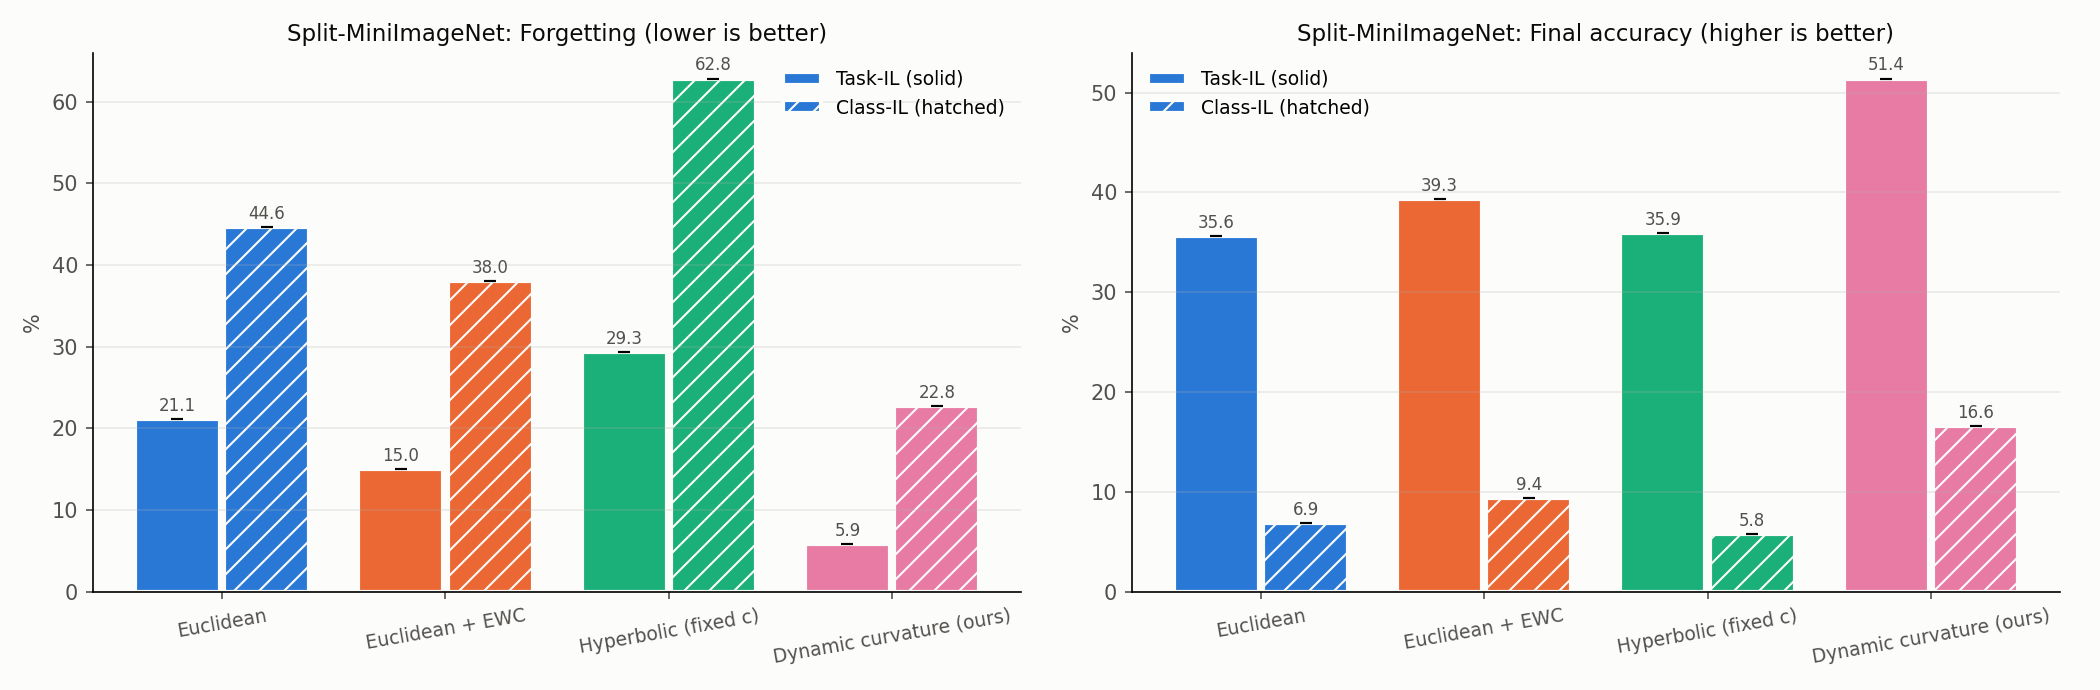

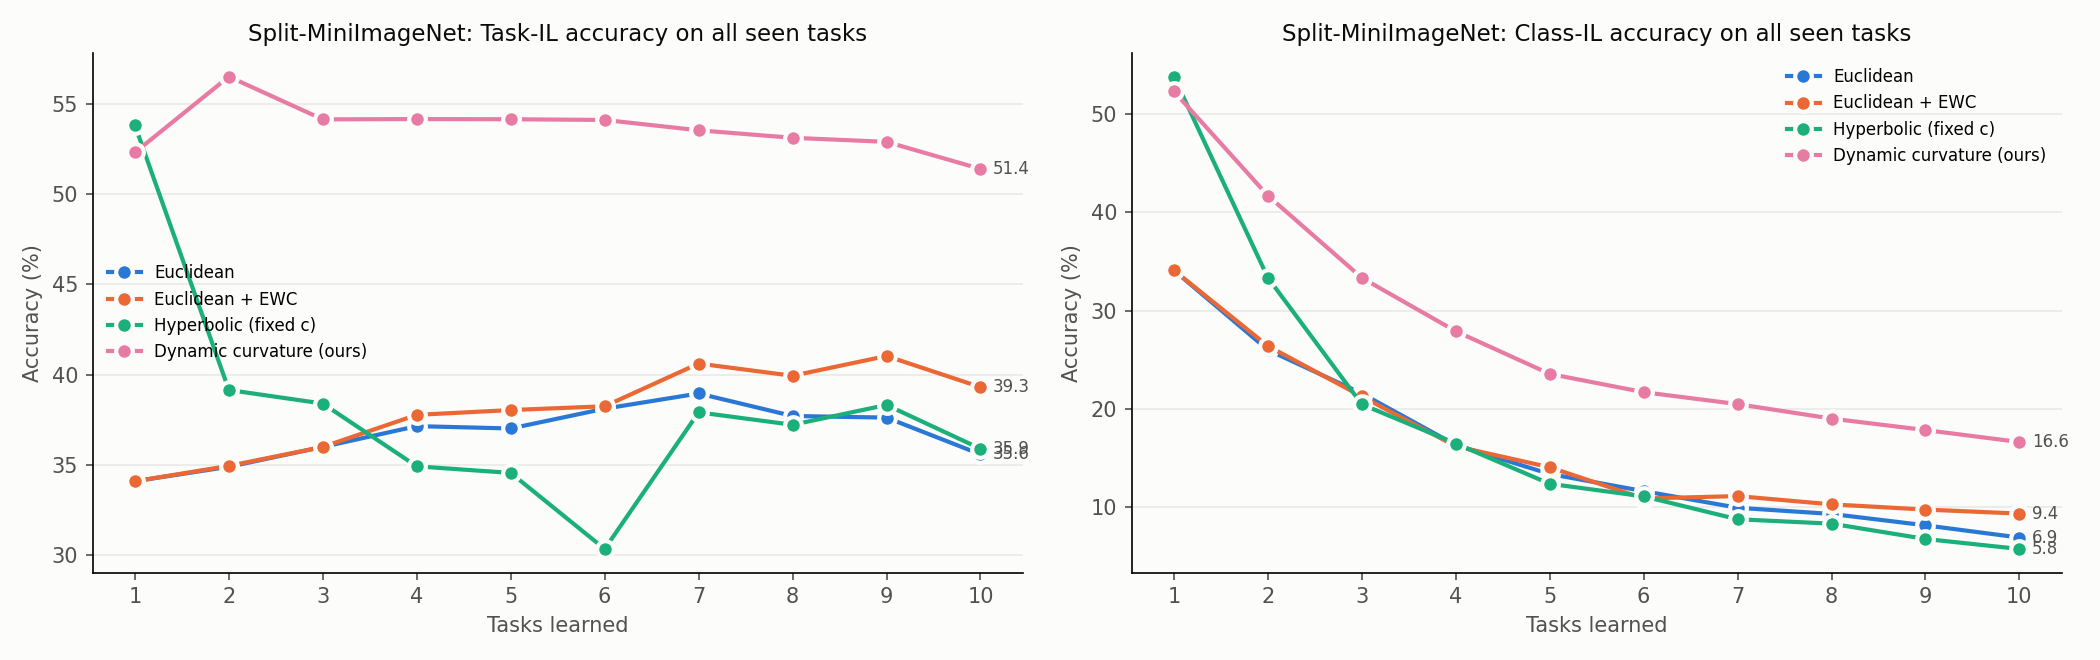

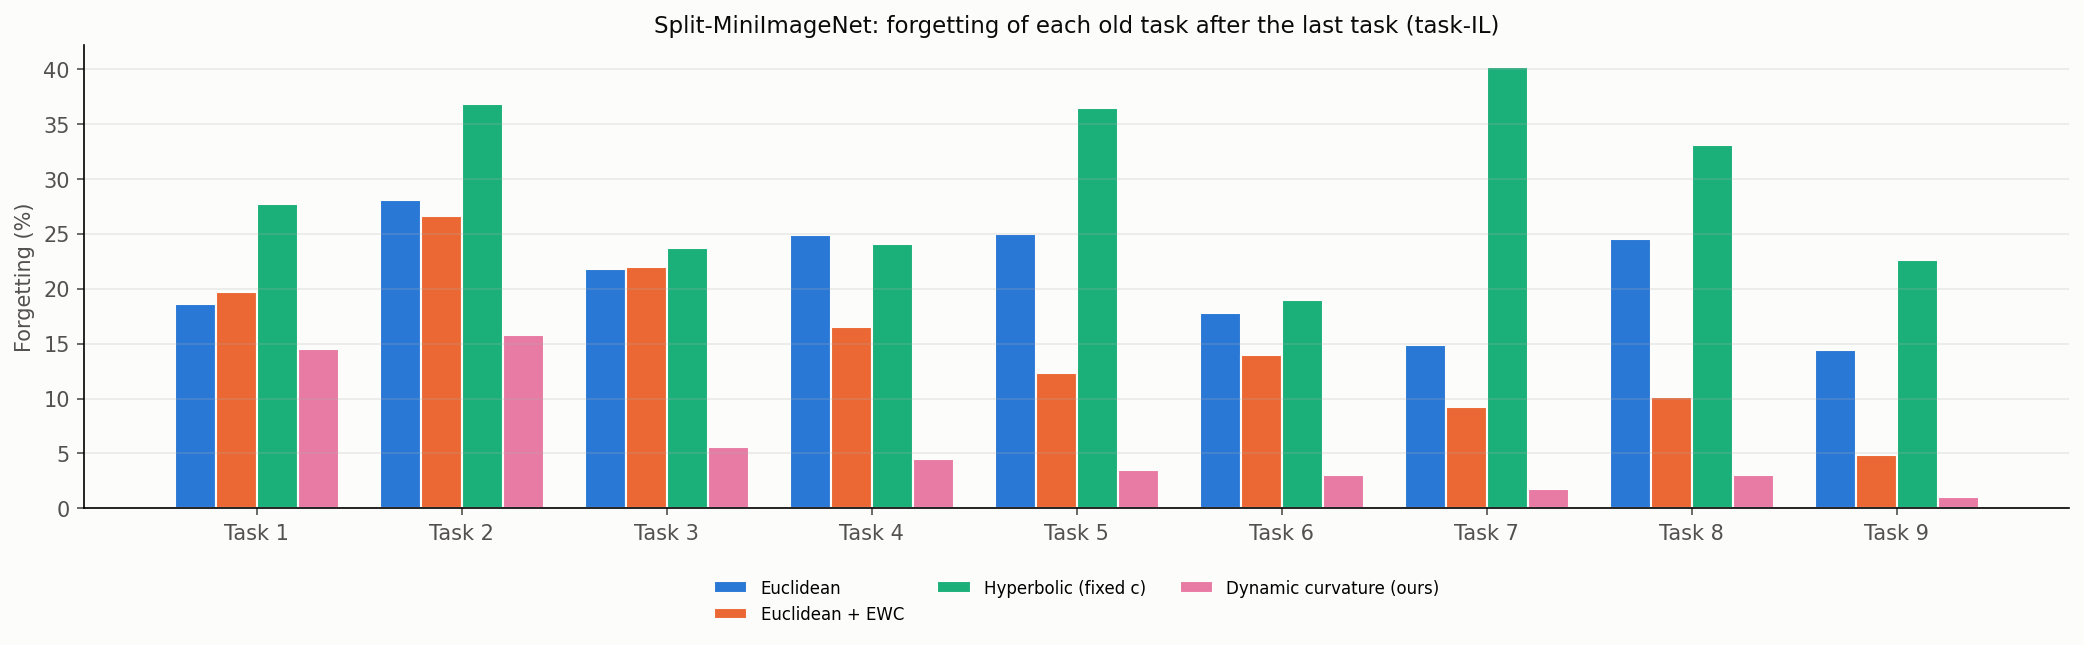


Tables and charts saved to /content/drive/MyDrive/hmcl_results_gpu/report


In [9]:
import sys, os, importlib
from IPython.display import display, Markdown, Image
sys.path.insert(0, '/content/hmcl'); import make_report as MR; importlib.reload(MR)

REPORT = f'{RESULTS}/report'
OURS = MR.OURS
runs = MR.load(RESULTS)
assert runs, f'No results found in {RESULTS}/<dataset>/'

for ds in ['split_cifar100', 'split_miniimagenet']:
    if ds not in runs:
        print(f'{ds}: no results yet'); continue
    order = [m for m in MR.LABEL if m in runs[ds]]
    out = f'{REPORT}/{ds}'; os.makedirs(out, exist_ok=True)
    display(Markdown(f'# {MR.DS_NAME[ds]}'))

    epochs = {m: next(iter(runs[ds][m].values())).get('epochs') for m in order}
    seeds = {m: sorted(runs[ds][m]) for m in order}
    if len(set(epochs.values())) > 1: print('WARNING: methods trained with different epochs:', epochs)
    if len({tuple(s) for s in seeds.values()}) > 1: print('WARNING: methods have different seeds:', seeds)
    print(f'epochs: {set(epochs.values())} | seeds: {seeds[order[0]]}')

    t = MR.results_table(runs[ds], order); open(f'{out}/results_table.md', 'w').write(t)
    display(Markdown('### Results (mean ± std over seeds)\n' + t))

    refs = [m for m in order if m != OURS]
    if OURS in runs[ds] and refs:
        imps = {r: MR.improvement(runs[ds], r) for r in refs}
        it = MR.improvement_table(imps); open(f'{out}/improvement_table.md', 'w').write(it)
        display(Markdown('### How much better is Dynamic curvature (ours)?\n' + it))
        e = imps.get('ewc')
        if e:
            print('Success metric (vs Euclidean + EWC): '
                  + ' | '.join(f"{tag}: {e[p]['forg_reduction_pct']:.0f}% less forgetting"
                               + (f" (p={e[p]['p']:.4f})" if e[p]['p'] is not None else ' (p n/a: 1 seed)')
                               for p, tag in MR.PROTOS))
        MR.chart_improvement(imps, ds, f'{out}/improvement.png'); display(Image(f'{out}/improvement.png'))

    MR.chart_bars(runs[ds], order, ds, f'{out}/forgetting_accuracy.png')
    MR.chart_curves(runs[ds], order, ds, f'{out}/accuracy_over_tasks.png')
    MR.chart_task_forgetting(runs[ds], order, ds, f'{out}/forgetting_per_task.png')
    for png in ('forgetting_accuracy', 'accuracy_over_tasks', 'forgetting_per_task'):
        display(Image(f'{out}/{png}.png'))

print(f'\nTables and charts saved to {REPORT}')
